<a href="https://colab.research.google.com/github/ilovemadfenmobile18-lab/doc-classification-ml/blob/main/notebooks/01_eda_and_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Загрузка датасета
df = pd.read_csv('dataset.csv')
df.head()

,text,doc_type,department
0,Просим подписать прилагаемый акт сверки взаимн...,Акт,Бухгалтерия
1,Срочно: просим подписать прилагаемый акт сверк...,Акт,Бухгалтерия
2,Входящий документ № 716. Просим подписать прил...,Акт,Бухгалтерия
3,Направляем подписанный акт сдачи-приемки выпол...,Акт,Бухгалтерия
4,Срочно: направляем подписанный акт сдачи-прием...,Акт,Бухгалтерия


In [4]:
# Анализ структуры выборки и проверка на пропуски
print(f"Размер выборки (строк, столбцов): {df.shape}")
print("\nПропущенные значения по столбцам:")
print(df.isnull().sum())
print(f"\nКоличество дубликатов: {df.duplicated(subset=['text']).sum()}")

Размер выборки (строк, столбцов): (120, 3)

Пропущенные значения по столбцам:
text          0
doc_type      0
department    0
dtype: int64

Количество дубликатов: 0


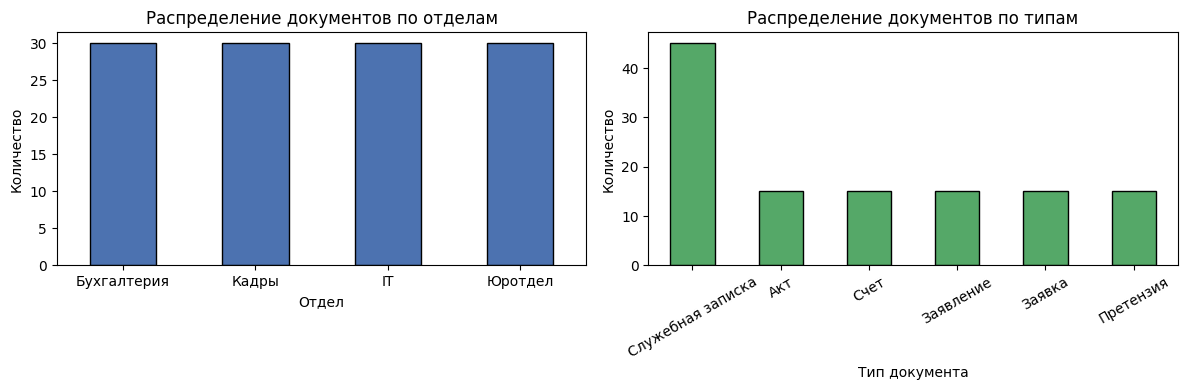

In [5]:
# Визуализация распределения классов целевых переменных (EDA)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Распределение по целевым отделам
df['department'].value_counts().plot(kind='bar', ax=axes[0], color='#4C72B0', edgecolor='black')
axes[0].set_title('Распределение документов по отделам')
axes[0].set_xlabel('Отдел')
axes[0].set_ylabel('Количество')
axes[0].tick_params(axis='x', rotation=0)

# Распределение по типам документов
df['doc_type'].value_counts().plot(kind='bar', ax=axes[1], color='#55A868', edgecolor='black')
axes[1].set_title('Распределение документов по типам')
axes[1].set_xlabel('Тип документа')
axes[1].set_ylabel('Количество')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [6]:
!pip install -q pymorphy3

import pymorphy3

# Разделение на train (70%), val (15%), test (15%) со стратификацией
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df['department']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df['department']
)

# Инициализация морфологического анализатора
morph = pymorphy3.MorphAnalyzer()

def preprocess_text(text: str) -> str:
    """Очистка текста от пунктуации и лемматизация."""
    clean = re.sub(r'[^а-яё\s]', ' ', text.lower())
    words = clean.split()
    lemmas = [morph.parse(w)[0].normal_form for w in words if len(w) > 2]
    return " ".join(lemmas)

# Применение предобработки к выборкам
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df['clean_text'] = train_df['text'].apply(preprocess_text)
val_df['clean_text'] = val_df['text'].apply(preprocess_text)
test_df['clean_text'] = test_df['text'].apply(preprocess_text)

print(f"Размеры выборок: Train = {len(train_df)}, Val = {len(val_df)}, Test = {len(test_df)}")
print("Исходный текст: ", train_df['text'].iloc[0])
print("Очищенный текст:", train_df['clean_text'].iloc[0])

Размеры выборок: Train = 84, Val = 18, Test = 18
Исходный текст:  Пропал доступ к базе данных СЭО на локальной машине, проверьте сетевую маршрутизацию и работу службы VPN.
Очищенный текст: пропасть доступ база данные сэо локальный машина проверить сетевой маршрутизация работа служба


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Инициализация TF-IDF векторизатора (униграммы + биграммы, порог встречаемости)
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=3000)

# Обучение векторизатора на обучающей выборке и трансформация всех сплитов
X_train = vectorizer.fit_transform(train_df['clean_text'])
X_val = vectorizer.transform(val_df['clean_text'])
X_test = vectorizer.transform(test_df['clean_text'])

# Выделение целевых переменных
y_train = train_df['department']
y_val = val_df['department']
y_test = test_df['department']

print(f"Размер словаря признаков: {len(vectorizer.get_feature_names_out())}")
print(f"Размерность матрицы X_train: {X_train.shape}")
print(f"Размерность матрицы X_val:   {X_val.shape}")
print(f"Размерность матрицы X_test:  {X_test.shape}")

Размер словаря признаков: 696
Размерность матрицы X_train: (84, 696)
Размерность матрицы X_val:   (18, 696)
Размерность матрицы X_test:  (18, 696)
